# Setup

- Load the "hyperparameters.json" file included in folder.


In [11]:
!pip install numpyro

# Libraries

In [12]:
import json

import numpy as np
import pandas as pd
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS
import jax
import jax.numpy as jnp

import matplotlib.pyplot as plt
import seaborn as sns

jax.config.update("jax_platforms", "cpu")
numpyro.set_host_device_count(4)
plt.style.use("bmh")


In [13]:
with open("hyperparameters.json") as f:
    model = json.load(f)
model["w"] = np.array(model["w"])


# In-house Model

In [14]:
def inhouse_model(t_obs, y_obs, x_comp, hyperparams):
    mu_u = hyperparams["mu_u"]
    sig_u = hyperparams["sig_u"]
    mu_logv = hyperparams["mu_logv"]
    sig_logv = hyperparams["sig_logv"]
    sig_y = hyperparams["sig_y"]
    w = jnp.array(hyperparams["w"])

    a_u = numpyro.sample("a_u", dist.Normal(0.0, 1.0))
    u = numpyro.deterministic("u", mu_u + a_u * sig_u)

    a_v = numpyro.sample("a_v", dist.Normal(0.0, 1.0))
    v = numpyro.deterministic("v", jnp.exp(mu_logv + a_v * sig_logv))

    v_eff = numpyro.deterministic("v_eff", v + jnp.dot(w, jnp.array(x_comp)))
    f = u * jnp.exp(-v_eff * jnp.array(t_obs) / 100.0)
    numpyro.sample("y", dist.Normal(f, sig_y), obs=jnp.array(y_obs))


def predict(index, day, model_obj):
    day = np.atleast_1d(np.array(day, dtype=float))

    t_obs = np.array(model_obj["t_obs"][index], dtype=float)
    y_obs = np.array(model_obj["y_obs"][index], dtype=float)
    x_comp = model_obj["x_comp"][index]

    mcmc = MCMC(NUTS(inhouse_model), num_warmup=1000, num_samples=2000, num_chains=4, progress_bar=False)
    mcmc.run(jax.random.PRNGKey(0), t_obs, y_obs, x_comp, model_obj)
    samples = mcmc.get_samples()

    u_s = samples["u"]
    v_eff_s = samples["v_eff"]
    f_pred = u_s[:, None] * jnp.exp(-v_eff_s[:, None] * jnp.array(day) / 100.0)
    pred_mean = np.array(jnp.mean(f_pred, axis=0))
    pred_std = np.array(jnp.std(f_pred, axis=0))

    if pred_mean.shape == (1,):
        return float(pred_mean[0]), float(pred_std[0])
    return pred_mean, pred_std

# Examples

Component 15 at t=50: mean=21.64, std=1.10
Component 60 at t=10: mean=61.92, std=3.24
Component 72 at t=30: mean=35.11, std=3.14


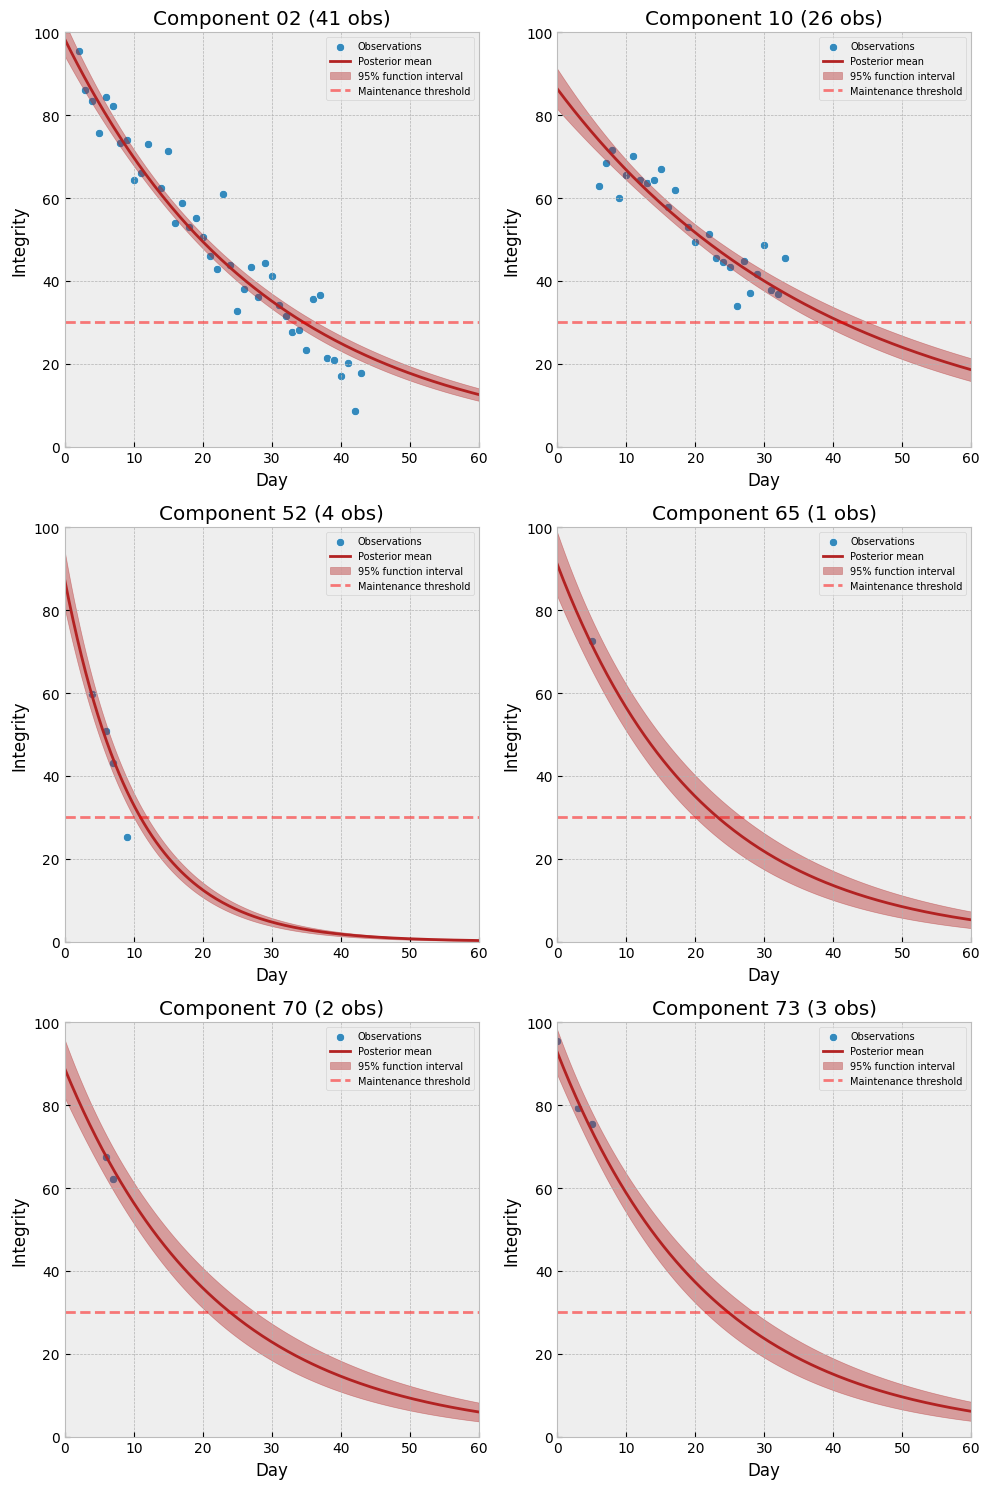

In [15]:
df = pd.read_csv("bml-component-data.csv")

model["t_obs"] = [df[df["index"] == i]["day"].values for i in range(75)]
model["y_obs"] = [df[df["index"] == i]["integrity"].values for i in range(75)]
model["x_comp"] = df.groupby("index")[["X1","X2","X3","X4","X5"]].first().values

# Checks
m15_at_50, s15_at_50 = predict(15, 50.0, model)
print(f"Component 15 at t=50: mean={m15_at_50:.2f}, std={s15_at_50:.2f}")

m60_at_10, s60_at_10 = predict(60, 10.0, model)
print(f"Component 60 at t=10: mean={m60_at_10:.2f}, std={s60_at_10:.2f}")

m72_at_30, s72_at_30 = predict(72, 30.0, model)
print(f"Component 72 at t=30: mean={m72_at_30:.2f}, std={s72_at_30:.2f}")

# Plots
days = np.linspace(0.0, 60.0, 200)
examples = [2, 10, 52, 65, 70, 73]

fig, axes = plt.subplots(3, 2, figsize=(10, 15))
for ax, idx in zip(axes.ravel(), examples):
    comp_data = df[df["index"] == idx]
    mean, std = predict(idx, days, model)

    sns.scatterplot(x=comp_data["day"], y=comp_data["integrity"], ax=ax, label="Observations")
    ax.plot(days, mean, color="Firebrick", label="Posterior mean")
    ax.fill_between(days, mean - 1.96*std, mean + 1.96*std, alpha=0.4, color="Firebrick", label="95% function interval")
    ax.axhline(30.0, linestyle="--", color="red", alpha=0.5, label="Maintenance threshold")
    ax.set_title(f"Component {idx:02d} ({len(comp_data)} obs)")
    ax.set_xlabel("Day")
    ax.set_ylabel("Integrity")
    ax.set_xlim(0.0, 60.0)
    ax.set_ylim(0.0, 100.0)
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()
